/tmp/ipykernel_392/4275124116.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Wine_Type', y='Price', ax=axes[0], palette='muted', errorbar=None)
/tmp/ipykernel_392/4275124116.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Quality_Score', y='Price', ax=axes[6], palette='coolwarm')


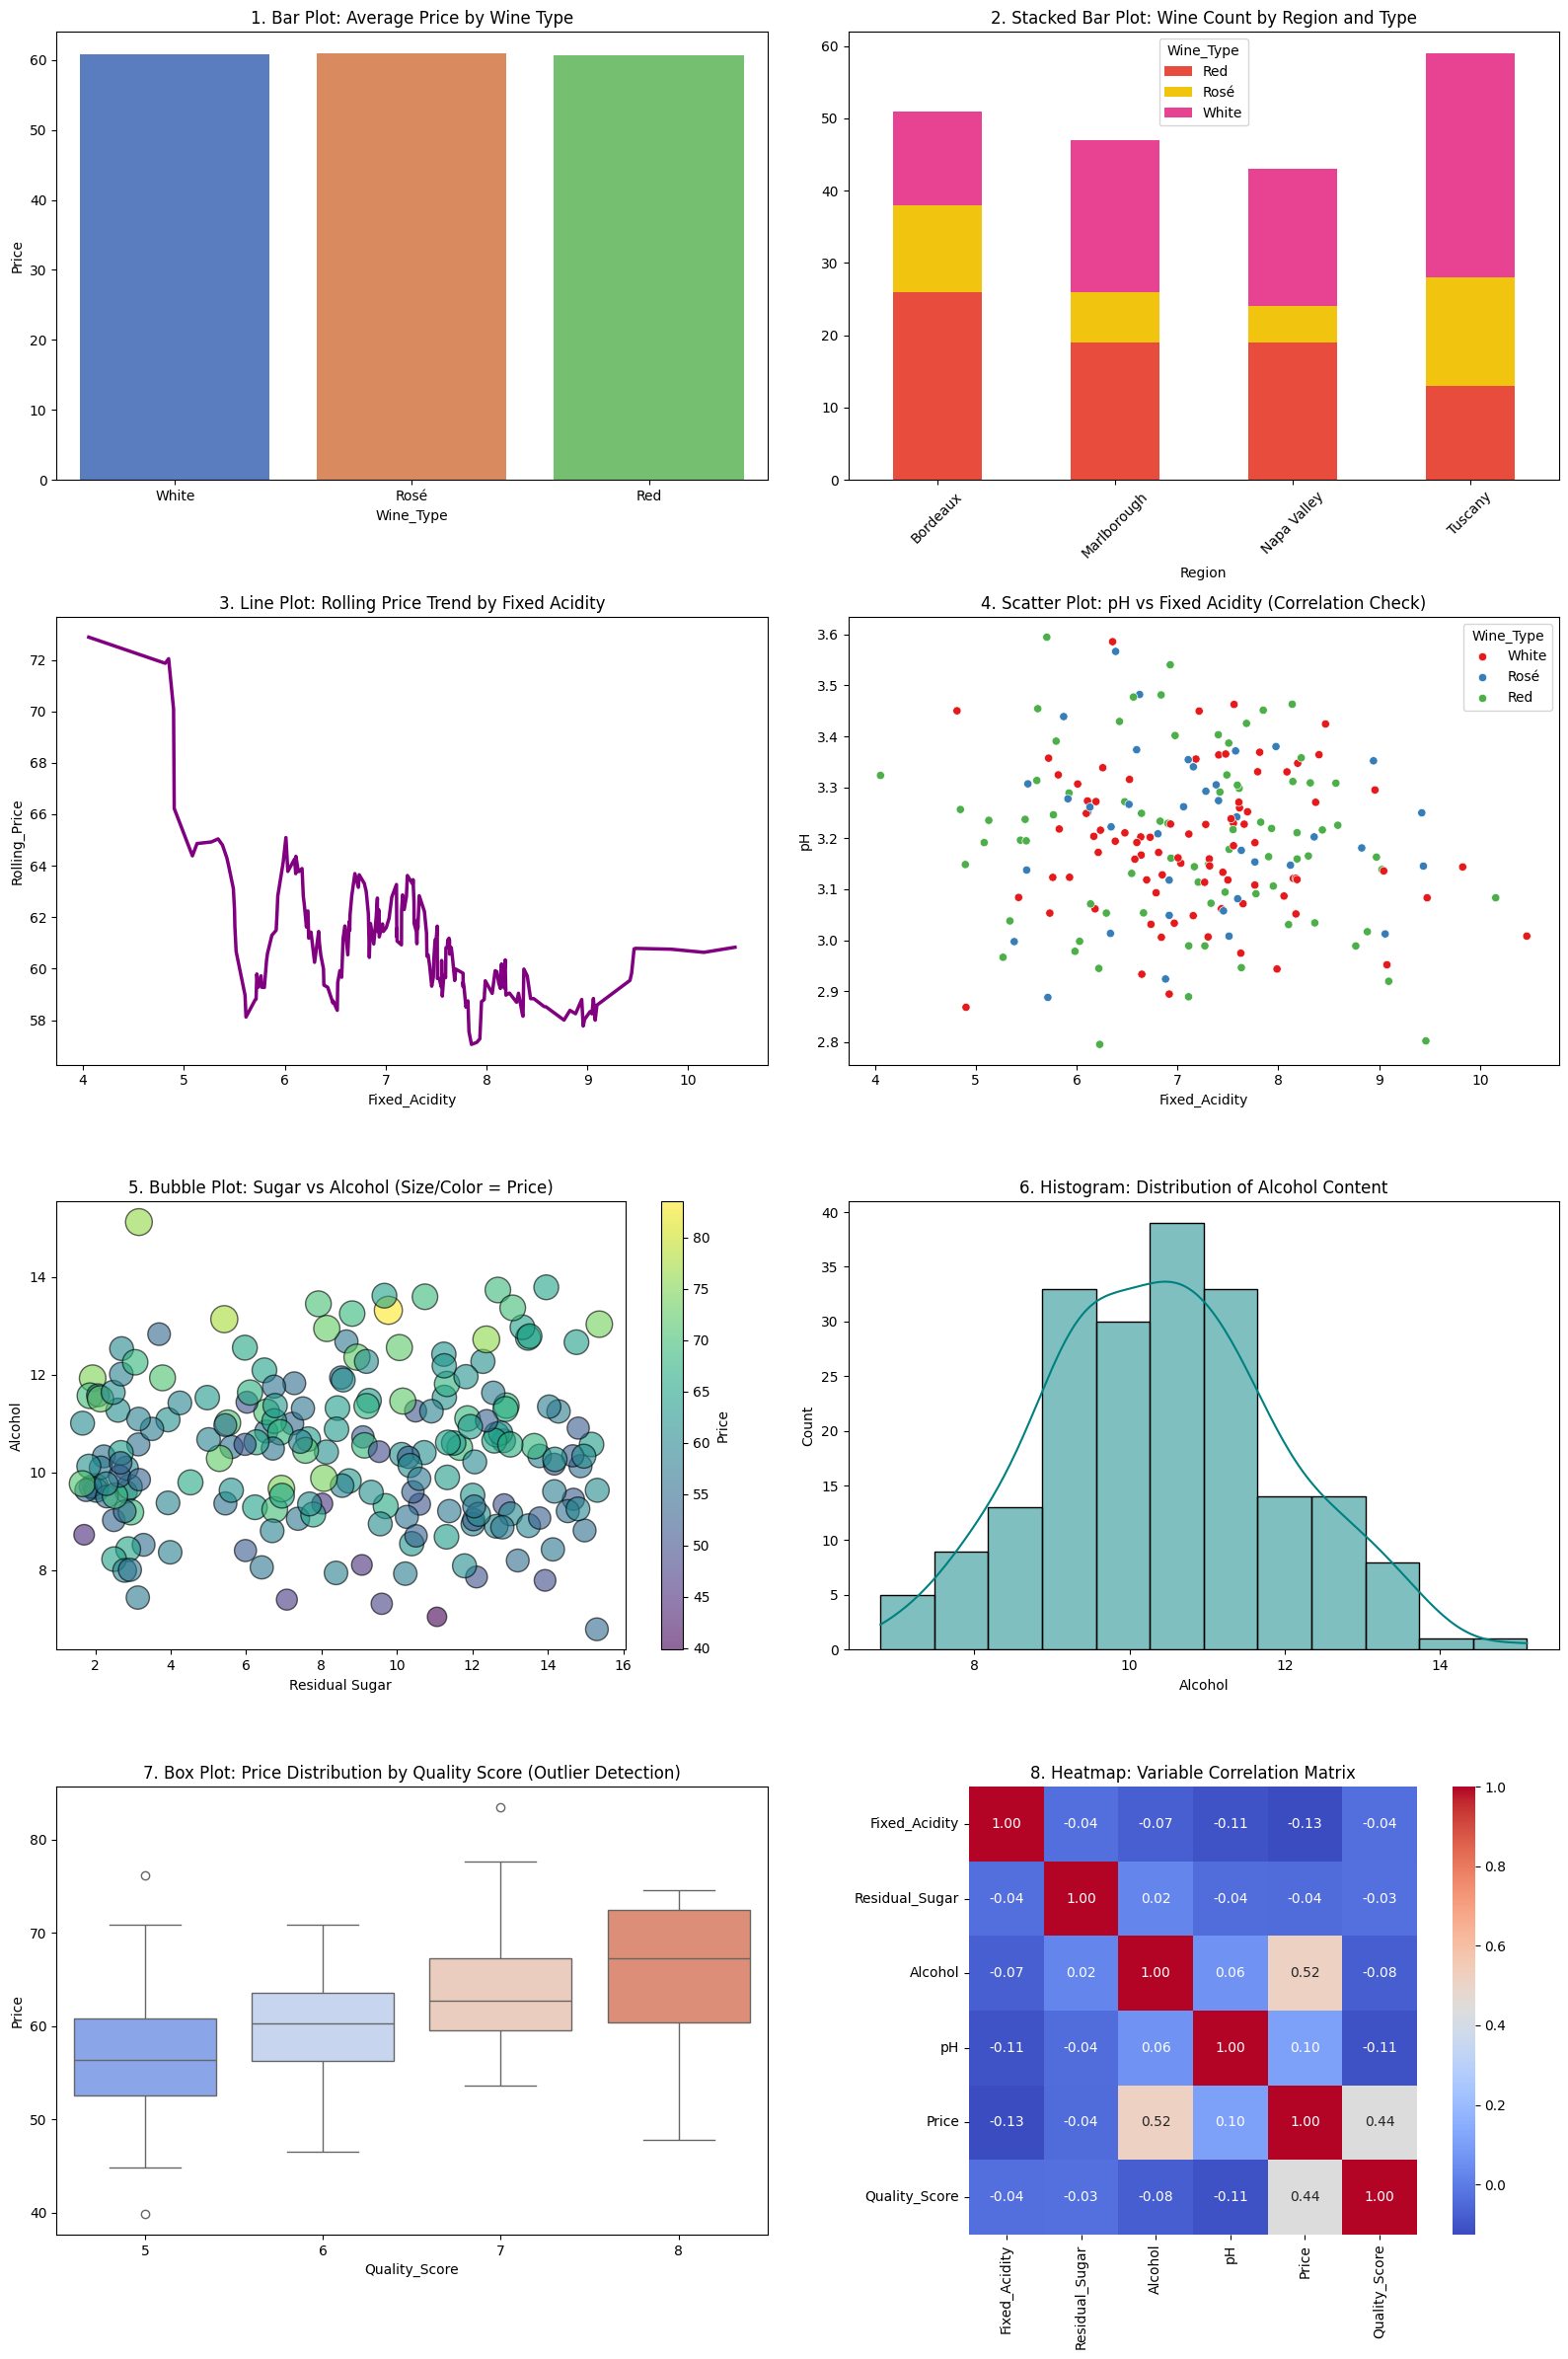

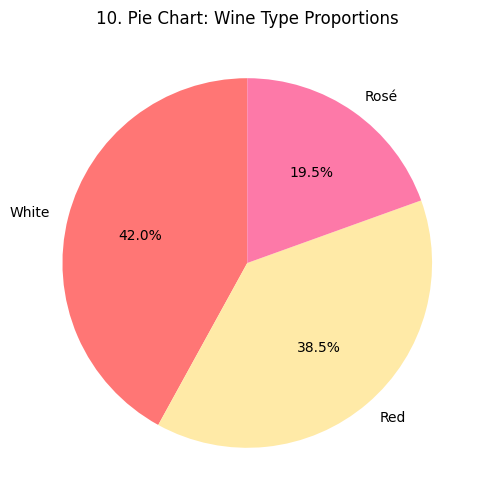

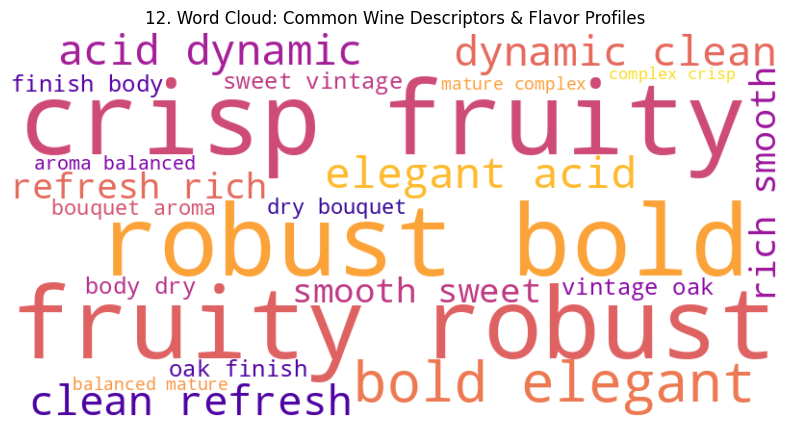

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from wordcloud import WordCloud

# 1. Create a synthetic multivariate wine-style dataset for complete visualization coverage
np.random.seed(42)
n_samples = 200
data = {
    'Fixed_Acidity': np.random.normal(7.2, 1.2, n_samples),
    'Residual_Sugar': np.random.uniform(1.5, 15.5, n_samples),
    'Alcohol': np.random.normal(10.5, 1.5, n_samples),
    'pH': np.random.normal(3.2, 0.15, n_samples),
    'Quality_Score': np.random.choice([5, 6, 7, 8], size=n_samples, p=[0.3, 0.4, 0.2, 0.1]),
    'Wine_Type': np.random.choice(['Red', 'White', 'Rosé'], size=n_samples, p=[0.4, 0.4, 0.2]),
    'Region': np.random.choice(['Tuscany', 'Bordeaux', 'Napa Valley', 'Marlborough'], size=n_samples)
}
df = pd.DataFrame(data)
df['Price'] = 10 + df['Alcohol'] * 2.5 + df['Quality_Score'] * 4 + np.random.normal(0, 5, n_samples)

# Prepare figures
fig, axes = plt.subplots(4, 2, figsize=(16, 24))
axes = axes.flatten()

# 1. Bar Plot: Average Price by Wine Type
sns.barplot(data=df, x='Wine_Type', y='Price', ax=axes[0], palette='muted', errorbar=None)
axes[0].set_title('1. Bar Plot: Average Price by Wine Type')

# 2. Stacked Bar Plot: Wine Count by Region and Type
region_type = df.groupby(['Region', 'Wine_Type']).size().unstack().fillna(0)
region_type.plot(kind='bar', stacked=True, ax=axes[1], color=['#e74c3c', '#f1c40f', '#e84393'])
axes[1].set_title('2. Stacked Bar Plot: Wine Count by Region and Type')
axes[1].tick_params(axis='x', rotation=45)

# 3. Line Plot: Trend of Price across sorted Fixed Acidity
sorted_df = df.sort_values(by='Fixed_Acidity')
sorted_df['Rolling_Price'] = sorted_df['Price'].rolling(window=15, min_periods=1).mean()
sns.lineplot(data=sorted_df, x='Fixed_Acidity', y='Rolling_Price', ax=axes[2], color='purple', linewidth=2.5)
axes[2].set_title('3. Line Plot: Rolling Price Trend by Fixed Acidity')

# 4. Scatter Plot: pH vs Fixed Acidity
sns.scatterplot(data=df, x='Fixed_Acidity', y='pH', hue='Wine_Type', ax=axes[3], palette='Set1')
axes[3].set_title('4. Scatter Plot: pH vs Fixed Acidity (Correlation Check)')

# 5. Bubble Plot: Residual Sugar vs Alcohol (Size mapped to Price)
scatter = axes[4].scatter(df['Residual_Sugar'], df['Alcohol'], s=df['Price']*5, c=df['Price'], cmap='viridis', alpha=0.6, edgecolors='black')
axes[4].set_xlabel('Residual Sugar')
axes[4].set_ylabel('Alcohol')
axes[4].set_title('5. Bubble Plot: Sugar vs Alcohol (Size/Color = Price)')
fig.colorbar(scatter, ax=axes[4], label='Price')

# 6. Histogram: Distribution of Alcohol content
sns.histplot(data=df, x='Alcohol', kde=True, ax=axes[5], color='teal')
axes[5].set_title('6. Histogram: Distribution of Alcohol Content')

# 7. Box Plot: Distribution of Price by Quality Score
sns.boxplot(data=df, x='Quality_Score', y='Price', ax=axes[6], palette='coolwarm')
axes[6].set_title('7. Box Plot: Price Distribution by Quality Score (Outlier Detection)')

# 8. Heatmap: Correlation matrix of numerical variables
corr = df[['Fixed_Acidity', 'Residual_Sugar', 'Alcohol', 'pH', 'Price', 'Quality_Score']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[7], square=True)
axes[7].set_title('8. Heatmap: Variable Correlation Matrix')

plt.tight_layout()
plt.show()

# 9. Radar Chart using Plotly
categories = ['Fixed_Acidity', 'Residual_Sugar', 'Alcohol', 'pH']
mean_metrics = df[categories].mean()
# Normalize mean metrics for visualization scale (0-10 index value representation)
normalized_means = [mean_metrics['Fixed_Acidity'], mean_metrics['Residual_Sugar'], mean_metrics['Alcohol'], mean_metrics['pH']*2]

fig_radar = px.line_polar(
    r=normalized_means + [normalized_means[0]],
    theta=categories + [categories[0]],
    line_close=True,
    title="9. Radar Chart: Mean Wine Characteristics Profile (pH scaled x2)"
)
fig_radar.update_traces(fill='toself')
fig_radar.show()

# 10. Pie Chart: Proportions of Wine Types
fig_pie, ax_pie = plt.subplots(figsize=(6, 6))
df['Wine_Type'].value_counts().plot.pie(autopct='%1.1f%%', colors=['#ff7675', '#ffeaa7', '#fd79a8'], startangle=90, ax=ax_pie)
ax_pie.set_ylabel('')
ax_pie.set_title('10. Pie Chart: Wine Type Proportions')
plt.show()

# 11. Tree Map of Regions and Wine Types
fig_tree = px.treemap(df, path=['Region', 'Wine_Type'], values='Price', title='11. Tree Map: Wine Value Distribution across Regions & Types')
fig_tree.show()

# 12. Word Cloud representing Wine Review keywords
wine_text = " ".join([
    "crisp fruity robust bold elegant acid dynamic clean refresh rich smooth sweet vintage oak finish body dry bouquet aroma balanced mature complex"
] * 10)
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='plasma').generate(wine_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('12. Word Cloud: Common Wine Descriptors & Flavor Profiles')
plt.show()

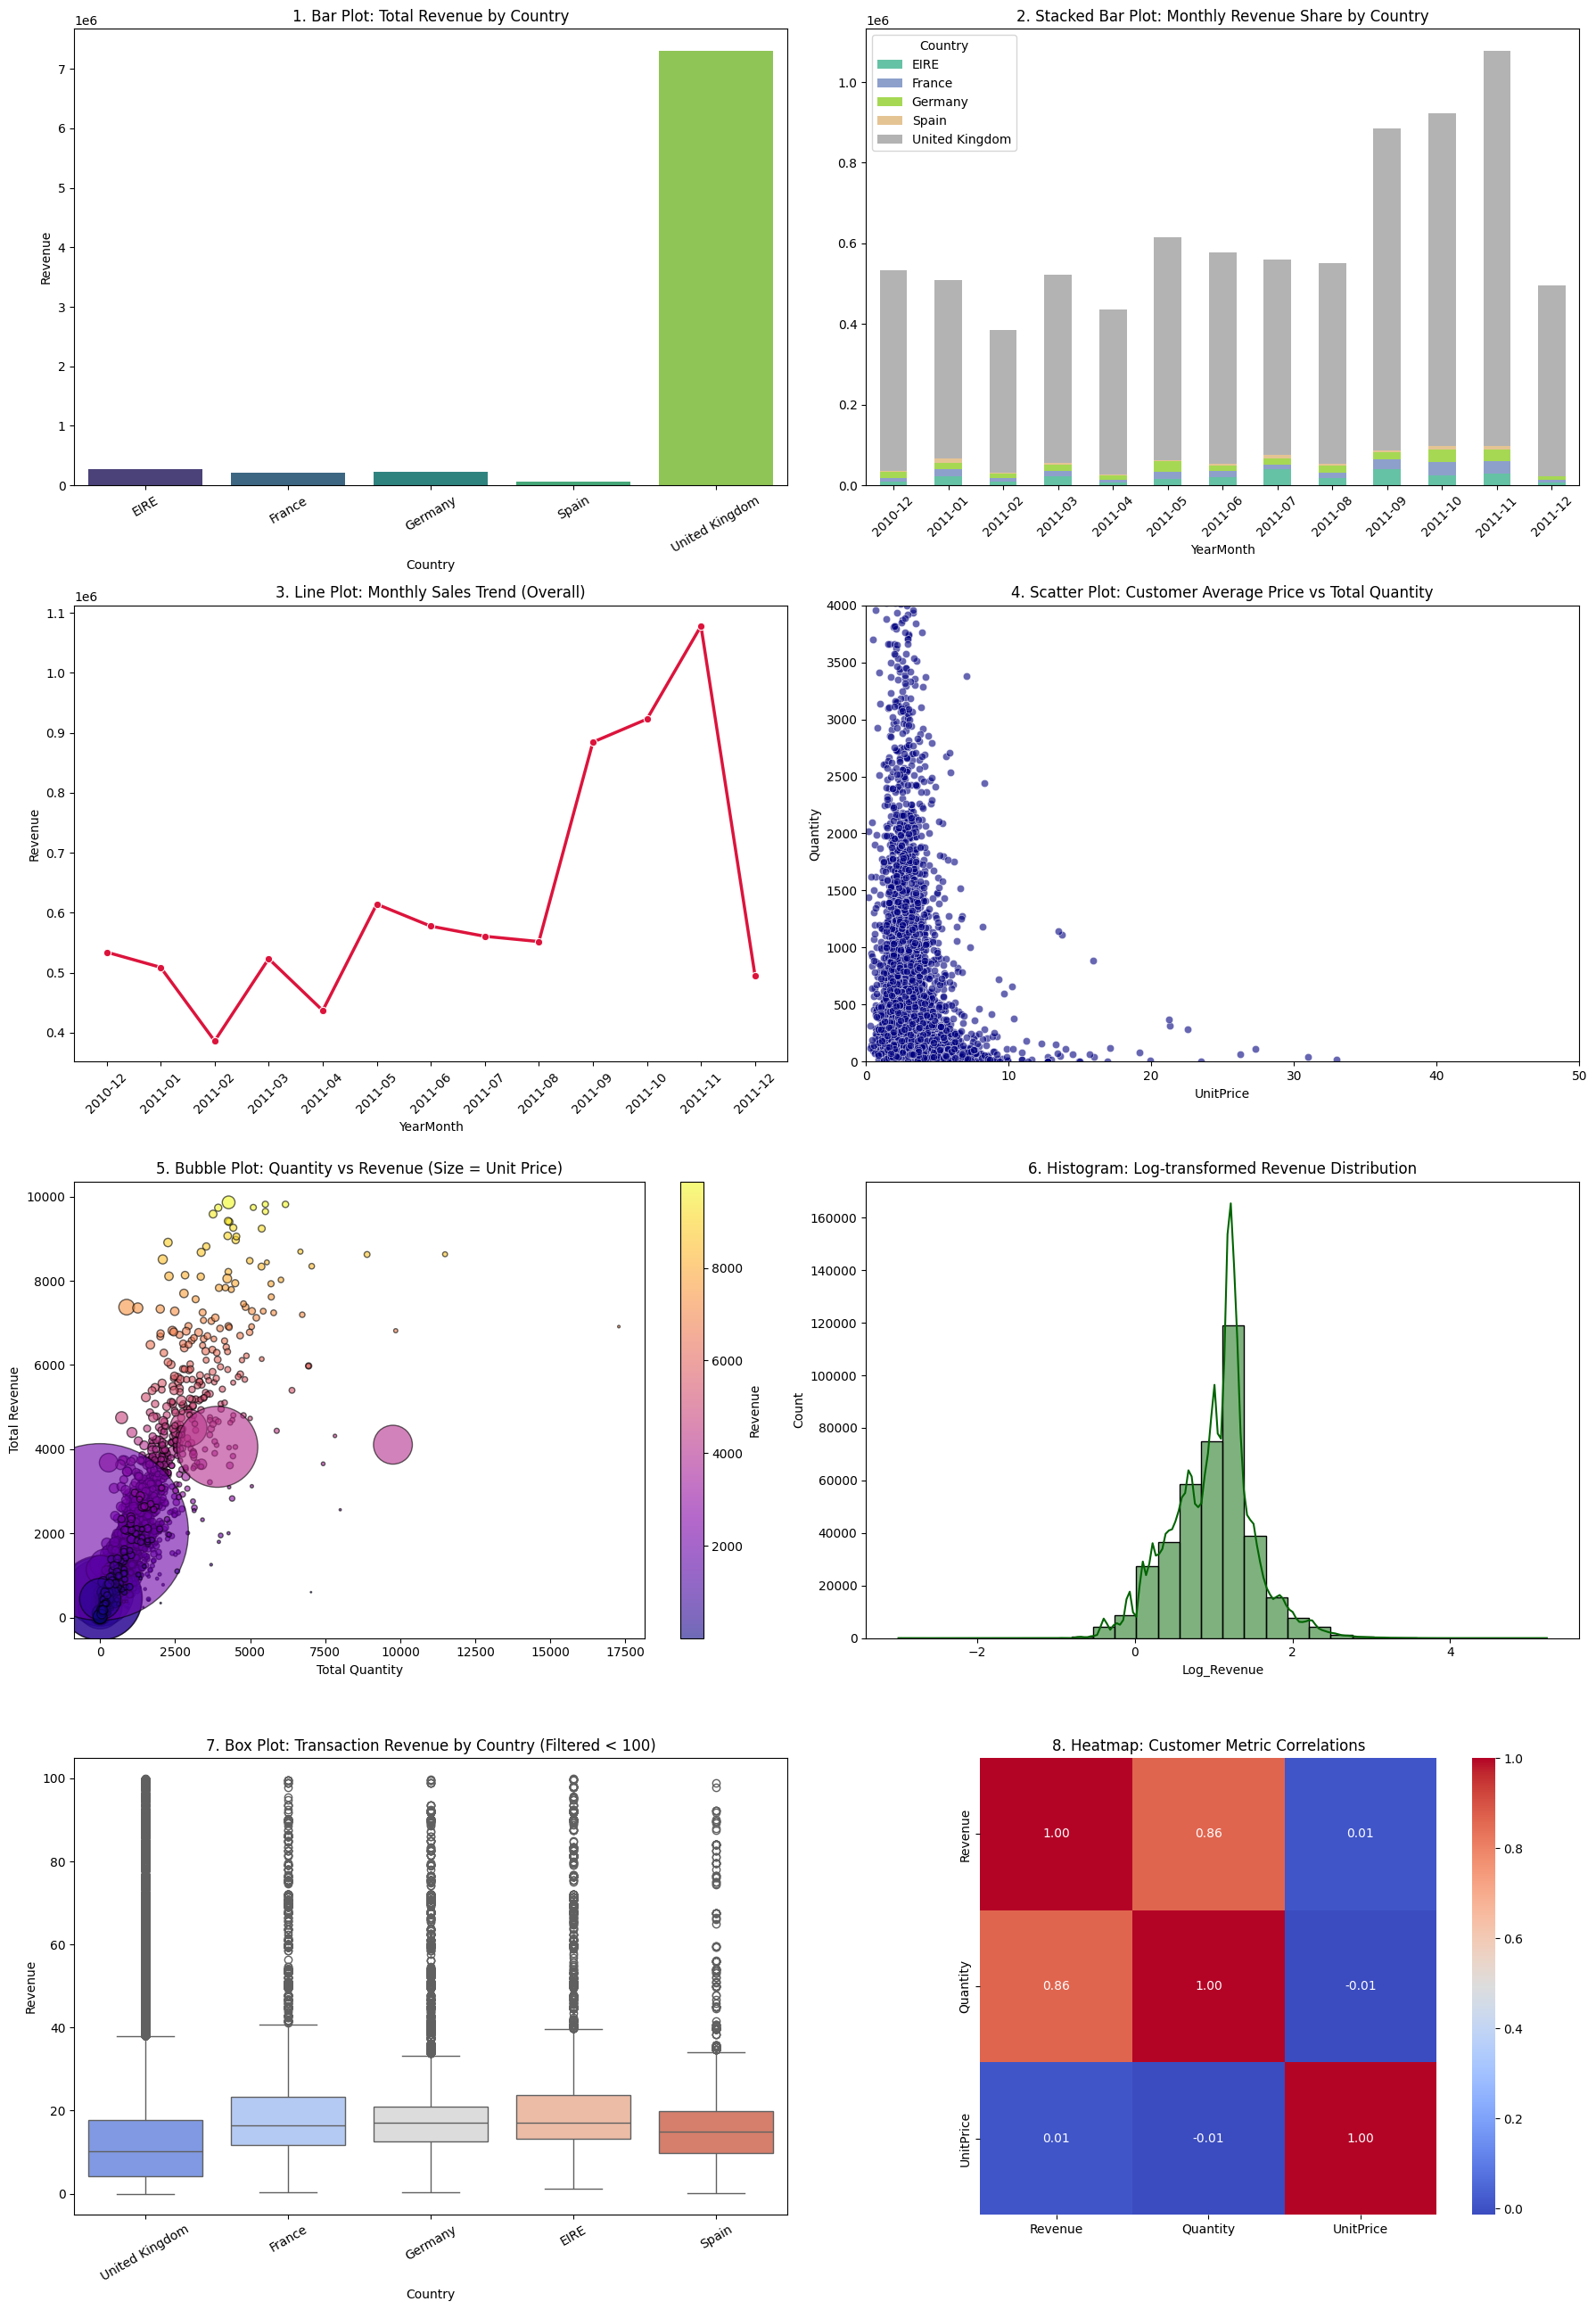

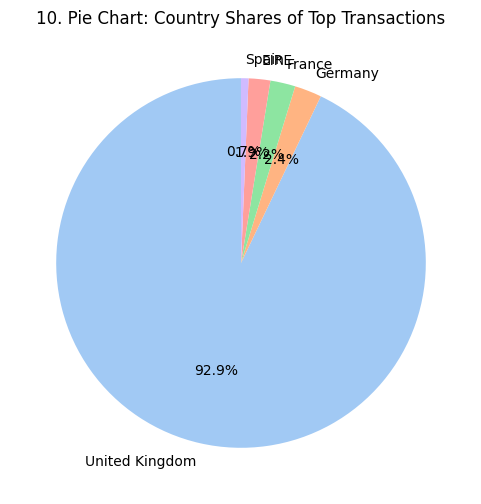

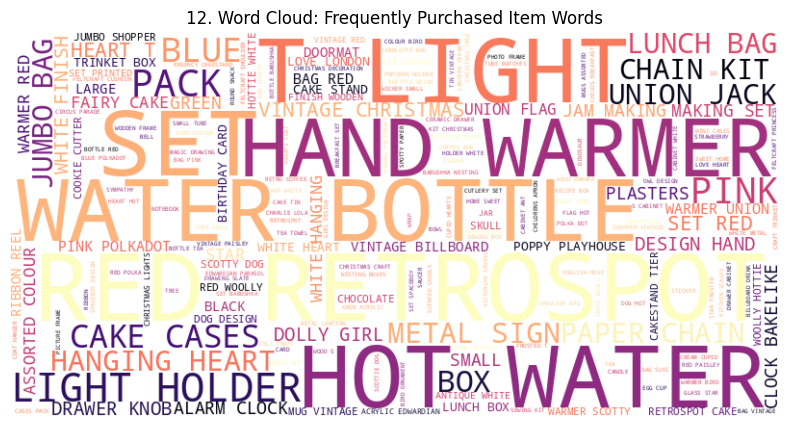

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from wordcloud import WordCloud
import datetime as dt

# 1. Load the real dataset
file_path = '/content/online_retail/Online Retail.xlsx'
df_retail = pd.read_excel(file_path)

# Clean and engineer features
df_retail = df_retail.dropna(subset=['CustomerID', 'Description'])
df_retail = df_retail[(df_retail['Quantity'] > 0) & (df_retail['UnitPrice'] > 0)]
df_retail['Revenue'] = df_retail['Quantity'] * df_retail['UnitPrice']
df_retail['InvoiceDate'] = pd.to_datetime(df_retail['InvoiceDate'])
df_retail['YearMonth'] = df_retail['InvoiceDate'].dt.to_period('M').astype(str)

# Filter top countries for clean visualization
top_countries = df_retail['Country'].value_counts().head(5).index.tolist()
df_top = df_retail[df_retail['Country'].isin(top_countries)].copy()

# Aggregate datasets for plots
country_revenue = df_top.groupby('Country')['Revenue'].sum().reset_index()
monthly_sales = df_top.groupby('YearMonth')['Revenue'].sum().reset_index()
country_monthly = df_top.groupby(['YearMonth', 'Country'])['Revenue'].sum().unstack().fillna(0)
customer_stats = df_top.groupby('CustomerID').agg({
    'Revenue': 'sum',
    'Quantity': 'sum',
    'UnitPrice': 'mean'
}).reset_index()
customer_stats = customer_stats[customer_stats['Revenue'] < 10000] # Cap outliers for better visualization

# Prepare subplots
fig, axes = plt.subplots(4, 2, figsize=(18, 26))
axes = axes.flatten()

# 1. Bar Plot: Revenue by Country
sns.barplot(data=country_revenue, x='Country', y='Revenue', ax=axes[0], palette='viridis', hue='Country', legend=False)
axes[0].set_title('1. Bar Plot: Total Revenue by Country')
axes[0].tick_params(axis='x', rotation=30)

# 2. Stacked Bar Plot: Monthly Revenue share by Country
country_monthly.plot(kind='bar', stacked=True, ax=axes[1], colormap='Set2')
axes[1].set_title('2. Stacked Bar Plot: Monthly Revenue Share by Country')
axes[1].tick_params(axis='x', rotation=45)

# 3. Line Plot: Monthly Sales Trend
sns.lineplot(data=monthly_sales, x='YearMonth', y='Revenue', marker='o', ax=axes[2], color='crimson', linewidth=2.5)
axes[2].set_title('3. Line Plot: Monthly Sales Trend (Overall)')
axes[2].tick_params(axis='x', rotation=45)

# 4. Scatter Plot: Quantity vs Average UnitPrice per Customer
sns.scatterplot(data=customer_stats, x='UnitPrice', y='Quantity', alpha=0.6, ax=axes[3], color='navy')
axes[3].set_xlim(0, 50)
axes[3].set_ylim(0, 4000)
axes[3].set_title('4. Scatter Plot: Customer Average Price vs Total Quantity')

# 5. Bubble Plot: Customer Revenue vs Quantity (Bubble Size = Average Unit Price)
scatter = axes[4].scatter(customer_stats['Quantity'], customer_stats['Revenue'],
                         s=customer_stats['UnitPrice']*10, c=customer_stats['Revenue'],
                         cmap='plasma', alpha=0.6, edgecolors='black')
axes[4].set_xlabel('Total Quantity')
axes[4].set_ylabel('Total Revenue')
axes[4].set_title('5. Bubble Plot: Quantity vs Revenue (Size = Unit Price)')
fig.colorbar(scatter, ax=axes[4], label='Revenue')

# 6. Histogram: Distribution of Log10 Revenue per transaction
df_retail['Log_Revenue'] = np.log10(df_retail['Revenue'])
sns.histplot(data=df_retail, x='Log_Revenue', kde=True, ax=axes[5], color='darkgreen', bins=30)
axes[5].set_title('6. Histogram: Log-transformed Revenue Distribution')

# 7. Box Plot: Revenue Distribution per Country (Outliers Check)
sns.boxplot(data=df_top[df_top['Revenue'] < 100], x='Country', y='Revenue', ax=axes[6], palette='coolwarm', hue='Country', legend=False)
axes[6].set_title('7. Box Plot: Transaction Revenue by Country (Filtered < 100)')
axes[6].tick_params(axis='x', rotation=30)

# 8. Heatmap: Correlation of Customer Transaction Metrics
corr_matrix = customer_stats[['Revenue', 'Quantity', 'UnitPrice']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[7], square=True)
axes[7].set_title('8. Heatmap: Customer Metric Correlations')

plt.tight_layout()
plt.show()

# 9. Radar Chart: Normalised Country Profile Metrics
features = ['Quantity', 'Revenue', 'UnitPrice']
country_profile = df_top.groupby('Country')[features].mean()
country_norm = (country_profile - country_profile.min()) / (country_profile.max() - country_profile.min())

fig_radar = px.line_polar(
    r=country_norm.iloc[0].values.tolist() + [country_norm.iloc[0].values[0]],
    theta=features + [features[0]],
    line_close=True,
    title=f"9. Radar Chart: Mean Normalised Profile for {country_norm.index[0]}"
)
fig_radar.update_traces(fill='toself')
fig_radar.show()

# 10. Pie Chart: Proportions of Transactions by top Countries
fig_pie, ax_pie = plt.subplots(figsize=(6, 6))
df_top['Country'].value_counts().plot.pie(autopct='%1.1f%%', colors=sns.color_palette('pastel'), startangle=90, ax=ax_pie)
ax_pie.set_ylabel('')
ax_pie.set_title('10. Pie Chart: Country Shares of Top Transactions')
plt.show()

# 11. Tree Map of Revenue by Country and Description
fig_tree = px.treemap(
    df_top.head(2000),
    path=['Country', 'Description'],
    values='Revenue',
    title='11. Tree Map: Top Revenue Distribution by Country & Item'
)
fig_tree.show()

# 12. Word Cloud representing Top Product Descriptions
product_descriptions = " ".join(df_retail['Description'].dropna().astype(str).tolist()[:5000])
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='magma').generate(product_descriptions)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('12. Word Cloud: Frequently Purchased Item Words')
plt.show()